# Give Me Some Credit: classify delinquency with a Random Forest

Train a Random Forest on the prepared credit data and inspect its held-out classification results. Complete the companion data-preparation notebook before running this lesson.

### Topics
- Load prepared training and test CSV files
- Select matching features
- Train a Random Forest classifier
- Interpret imbalanced-class metrics and prediction errors

**Question for the lesson:** Does the model detect delinquency effectively, beyond achieving high overall accuracy?

> **Estimated time: 30 min**

## 1 · Import the tools

Use Pandas to load prepared tables, a Random Forest classifier to predict delinquency, and classification metrics and Matplotlib to inspect errors. The imported splitting function is not used because the files already contain separate training and test subsets.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

## 2 · Load the prepared training data

Run `give_me_some_credit.ipynb` first to generate `train.csv` and `test.csv` in this folder. Load the training export and inspect the columns, including the target and engineered repayment features.

In [2]:
train_data = pd.read_csv('train.csv')
train_data

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,SeriousDlqin,MonthlyIncome_missing,Is_Outlier,TotalPastDue,Has90DaysLate,WorstDelayStatus
0,0.000000,45,0,0.460931,3416.0,5,0,2,0,2.0,0,0,False,0,0,0
1,0.639249,42,1,0.259114,19666.0,10,0,1,0,3.0,0,0,True,1,0,1
2,0.058665,44,0,0.295182,4254.0,12,0,2,0,1.0,0,0,False,0,0,0
3,0.016730,49,0,9.000000,5400.0,1,0,0,0,0.0,0,1,True,0,0,0
4,0.380152,61,0,8268.000000,5400.0,25,0,7,0,0.0,0,1,True,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104985,0.043749,69,0,95.000000,5400.0,6,0,0,0,0.0,0,1,True,0,0,0
104986,0.037411,34,0,0.078970,6951.0,8,0,0,0,0.0,0,0,False,0,0,0
104987,0.000000,56,0,0.190977,3900.0,9,0,0,0,1.0,0,0,False,0,0,0
104988,0.276532,34,0,0.068928,2770.0,6,0,0,0,0.0,0,0,False,0,0,0


## 3 · Load the prepared test data

This file contains the previously held-out rows, transformed using the training-set medians and matching feature definitions. Keep these rows out of model fitting.

In [3]:
test_data = pd.read_csv('test.csv')
test_data

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,SeriousDlqin,MonthlyIncome_missing,TotalPastDue,Has90DaysLate,WorstDelayStatus
0,0.727458,44,3,0.778059,7100.0,8,0,1,1,3.0,1,0,4,0,2
1,0.002731,74,0,0.000000,5400.0,4,0,0,0,0.0,0,1,0,0,0
2,0.080355,50,0,135.000000,5400.0,5,0,0,0,2.0,0,1,0,0,0
3,0.489061,42,0,1603.000000,5400.0,11,0,0,0,3.0,0,1,0,0,0
4,0.042558,86,0,0.004428,7000.0,7,0,0,0,0.0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44991,0.452636,66,0,0.536866,4000.0,8,1,1,0,0.0,1,0,1,1,3
44992,0.364688,83,0,0.909032,1549.0,12,0,1,0,0.0,0,0,0,0,0
44993,0.919156,58,0,0.411791,6784.0,8,0,2,0,0.0,0,0,0,0,0
44994,0.008375,64,0,1722.000000,5400.0,5,0,1,0,0.0,0,1,0,0,0


## 4 · Select training features and target

Use `SeriousDlqin` as the target: `1` indicates serious delinquency and `0` its absence. Remove it from the predictors along with `Is_Outlier`, a training-only diagnostic flag. All remaining predictors must be numerical and free of unsupported missing values.

In [4]:
X_train = train_data.drop(columns=['SeriousDlqin', "Is_Outlier"])
y_train = train_data['SeriousDlqin']

## 5 · Train a Random Forest classifier

Fit 100 trees using the prepared training rows. Each tree learns from a bootstrap sample and random feature subsets; the forest averages class probabilities to predict an outcome. `random_state=42` makes training reproducible. This example uses the default class weighting and prediction rule.

In [5]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

## 6 · Prepare matching test inputs

Separate the test target from its predictors. Predictor names and order must match `X_train` exactly. The preparation notebook does not add `Is_Outlier` to test data, so only the target is dropped here. If you change either export, verify the two schemas before predicting.

In [6]:
X_test = test_data.drop(columns=['SeriousDlqin'])
y_test = test_data['SeriousDlqin']

## 7 · Evaluate delinquency predictions

Predict the held-out rows and inspect accuracy together with the per-class report. For delinquency (`1`), precision measures how many flagged customers actually have the outcome; recall measures how many actual delinquent customers are detected. F1 balances the two, and support counts the true examples of each class.

Compare accuracy with the majority-class share. A high accuracy can hide poor delinquency recall when class `1` is rare.

In [7]:
y_pred = rf_classifier.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Classification Report:")
print(classification_rep)

Accuracy: 0.9349053249177705
Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.97     41988
           1       0.54      0.19      0.28      3008

    accuracy                           0.93     44996
   macro avg       0.74      0.59      0.62     44996
weighted avg       0.92      0.93      0.92     44996



## 8 · Interpret the confusion matrix

Rows are actual classes and columns are predicted classes. `Class 0` means no serious delinquency; `Class 1` means serious delinquency.

- Top left: correctly predicted non-delinquent customers.
- Top right: non-delinquent customers incorrectly flagged.
- Bottom left: delinquent customers the model missed.
- Bottom right: correctly detected delinquent customers.

### Pause & discuss

Which error is more costly in the intended lending workflow? How would that affect your choice of evaluation metric and decision threshold?

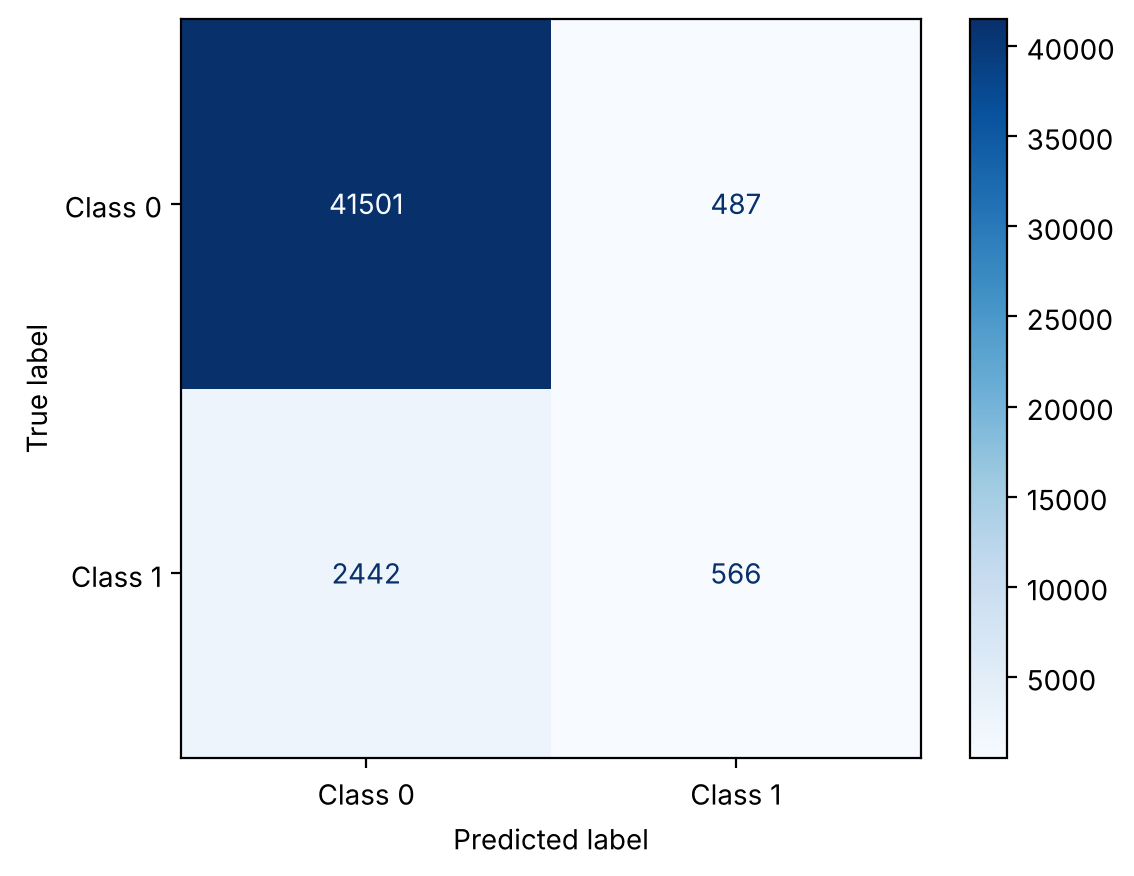

In [8]:
cm = confusion_matrix(y_test, y_pred)

# 2. Plot the matrix visually
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1'])
disp.plot(cmap=plt.cm.Blues)
plt.show()

## B · Delinquency metrics (class 1) and why accuracy alone misleads

Below, the per-class report is turned into a small table for **delinquency (`SeriousDlqin = 1`)**, next to the majority-class baseline and a clearly labelled confusion matrix.

,Precision,Recall,F1-score,Support
Delinquent (1),0.5375,0.1882,0.2787,3008


Random Forest accuracy              : 0.9349
Always-predict-"no delinquency" acc.: 0.9331   (a model that never detects anything)


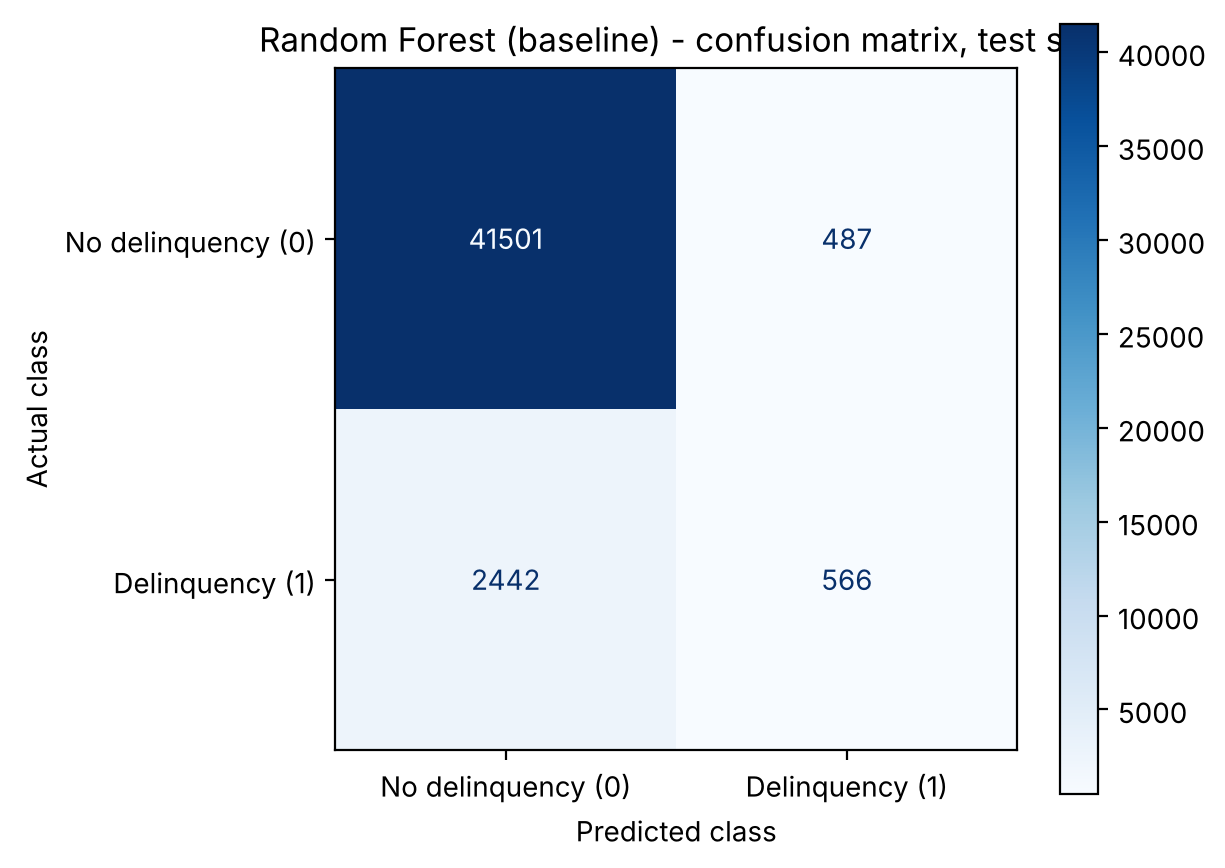

In [9]:
rep = classification_report(y_test, y_pred, output_dict=True)
dlq = pd.DataFrame({'Precision': rep['1']['precision'], 'Recall': rep['1']['recall'],
                    'F1-score': rep['1']['f1-score'], 'Support': int(rep['1']['support'])}, index=['Delinquent (1)'])
display(dlq.round(4))

majority_acc = (y_test == 0).mean()
print(f'Random Forest accuracy              : {accuracy:.4f}')
print(f'Always-predict-"no delinquency" acc.: {majority_acc:.4f}   (a model that never detects anything)')

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=['No delinquency (0)', 'Delinquency (1)']).plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Random Forest (baseline) - confusion matrix, test set')
ax.set_xlabel('Predicted class'); ax.set_ylabel('Actual class'); plt.show()

**Why accuracy alone is misleading.** Only 6.7 % of the customers are delinquent, so a model that *never* flags anyone already scores **93.3 %** accuracy. The default Random Forest scores **93.5 %**, barely above that, yet for delinquency (class 1) its **recall is only 0.19** (it finds about 566 of the 3,008 delinquent test customers and misses roughly 2,440), precision is 0.54 and F1 is 0.28. The 99 % recall on class 0 dominates the accuracy figure and hides the failure on the class that matters. In lending a missed delinquent customer (false negative) is usually far more costly than a wrongly flagged good customer, so recall, precision/F1 on class 1, PR-AUC or a cost-weighted metric are better yardsticks than accuracy.

## C · Can we increase accuracy? Balancing, outlier removal, a different classifier, tuned hyper-parameters

**Protocol (no test leakage).** All choices are made on a *validation* split carved out of the training file (80 % fit / 20 % validation, stratified, `random_state=42`). Every learned quantity (outlier thresholds, SMOTENC synthetic rows) is computed from the fitting rows only, and the test set is used once at the end.

Techniques compared:

1. **Balancing**: `SMOTENC` (oversampling with synthetic minority rows; the binary/ordinal flags `MonthlyIncome_missing`, `Has90DaysLate`, `WorstDelayStatus` are passed as categorical) with `sampling_strategy=0.3` (minority = 30 % of majority). Applied to fitting rows only.
2. **Outlier removal from the training set**: the notebook's `Is_Outlier` flag (IQR rule on every column) marks about half of all rows, and those rows are *more* delinquent than average, so deleting them would discard most of the signal. Instead, only **extreme** rows are removed: values above the 99.5th percentile of `RevolvingUtilizationOfUnsecuredLines`, `DebtRatio` and `MonthlyIncome`, plus the placeholder codes 96/98 in the three past-due counters. Thresholds come from the fitting rows.
3. **Classifier**: `RandomForestClassifier` vs. `HistGradientBoostingClassifier`.
4. **Hyper-parameter tuning**: `RandomizedSearchCV` (3-fold, scored by accuracy) for the best configuration.

In [10]:
import numpy as np
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, recall_score, precision_score

SEED = 42
cat_cols = ['MonthlyIncome_missing', 'Has90DaysLate', 'WorstDelayStatus']
cat_idx = [X_train.columns.get_loc(c) for c in cat_cols]
cont_cols = ['RevolvingUtilizationOfUnsecuredLines', 'DebtRatio', 'MonthlyIncome']
code_cols = ['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfTimes90DaysLate']

def fit_outlier_rule(X_fit, q=0.995):
    return {c: X_fit[c].quantile(q) for c in cont_cols}

def keep_mask(X_, limits):
    ok = pd.Series(True, index=X_.index)
    for c, hi in limits.items():
        ok &= X_[c] <= hi
    for c in code_cols:
        ok &= ~X_[c].isin([96, 98])
    return ok

def make_model(kind, **params):
    if kind == 'RandomForest':
        return RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1, **params)
    return HistGradientBoostingClassifier(random_state=SEED, **params)

def prepare(X_fit, y_fit, remove_outliers, balance):
    if remove_outliers:
        keep = keep_mask(X_fit, fit_outlier_rule(X_fit))
        X_fit, y_fit = X_fit[keep], y_fit[keep]
    if balance:
        X_fit, y_fit = SMOTENC(categorical_features=cat_idx, sampling_strategy=0.3, random_state=SEED).fit_resample(X_fit, y_fit)
    return X_fit, y_fit

def scores(y_true, y_hat):
    return {'Accuracy': accuracy_score(y_true, y_hat), 'Recall (1)': recall_score(y_true, y_hat),
            'Precision (1)': precision_score(y_true, y_hat, zero_division=0), 'F1 (1)': f1_score(y_true, y_hat)}

# validation split from the TRAINING data only
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
print('fit:', X_fit.shape, ' validation:', X_val.shape, ' | delinquency rate fit/val: %.4f / %.4f' % (y_fit.mean(), y_val.mean()))
lim = fit_outlier_rule(X_fit)
print('rows removed as extreme outliers: %d of %d (%.2f %%)' % ((~keep_mask(X_fit, lim)).sum(), len(X_fit), 100 * (~keep_mask(X_fit, lim)).mean()))

fit: (83992, 14)  validation: (20998, 14)  | delinquency rate fit/val: 0.0668 / 0.0668
rows removed as extreme outliers: 1416 of 83992 (1.69 %)


In [11]:
rows = []
for kind in ['RandomForest', 'HistGradientBoosting']:
    for rm in [False, True]:
        for bal in [False, True]:
            Xf, yf = prepare(X_fit, y_fit, rm, bal)
            m = make_model(kind).fit(Xf, yf)
            rows.append({'Classifier': kind, 'Outliers removed': rm, 'SMOTENC': bal, 'Fit rows': len(Xf), **scores(y_val, m.predict(X_val))})
grid = pd.DataFrame(rows).sort_values('Accuracy', ascending=False).reset_index(drop=True)
print(f'Validation majority-class accuracy: {(y_val == 0).mean():.4f}')
grid.round(4)

Validation majority-class accuracy: 0.9332


,Classifier,Outliers removed,SMOTENC,Fit rows,Accuracy,Recall (1),Precision (1),F1 (1)
0,HistGradientBoosting,True,False,82576,0.9372,0.1896,0.5938,0.2874
1,HistGradientBoosting,False,False,83992,0.9370,0.1789,0.5962,0.2752
2,RandomForest,True,False,82576,0.9361,0.1953,0.5638,0.2901
3,RandomForest,False,False,83992,0.9360,0.1960,0.5601,0.2904
4,HistGradientBoosting,True,True,100387,0.9338,0.2659,0.5089,0.3493
5,HistGradientBoosting,False,True,101891,0.9314,0.3165,0.4800,0.3814
6,RandomForest,True,True,100387,0.9309,0.2651,0.4691,0.3388
7,RandomForest,False,True,101891,0.9292,0.3036,0.4551,0.3643


**Reading the grid (validation).**

- **Classifier:** gradient boosting beats the Random Forest in accuracy (0.9370 vs 0.9360 without balancing).
- **Outlier removal:** removing the ~1.7 % extreme rows gives a small, consistent gain (+0.0001 to +0.0024 accuracy), but the effect is within noise.
- **Balancing (SMOTENC):** it *lowers* accuracy (e.g. 0.9370 → 0.9314) while raising delinquency recall from ≈0.18 to ≈0.32 and F1 from ≈0.28 to ≈0.38. The model now flags more customers, so it makes more false alarms on the (dominant) good class, which costs accuracy. Accuracy and delinquency detection trade off against each other.
- Differences in accuracy are in the 3rd decimal, so *all* of them are small compared with the 0.933 majority-class baseline: there is little accuracy to gain from this feature set.

In [12]:
best = grid.iloc[0]
print('Best on validation accuracy:', dict(best[['Classifier', 'Outliers removed', 'SMOTENC']]))

# tune the best classifier on the best preprocessing; SMOTENC (if chosen) runs inside each CV fold via an imblearn pipeline
Xf, yf = X_fit.copy(), y_fit.copy()
if best['Outliers removed']:
    keep = keep_mask(Xf, fit_outlier_rule(Xf)); Xf, yf = Xf[keep], yf[keep]

if best['Classifier'] == 'RandomForest':
    space = {'clf__n_estimators': [100, 200, 300], 'clf__max_depth': [None, 8, 12, 20],
             'clf__min_samples_leaf': [1, 5, 10, 20], 'clf__max_features': ['sqrt', 0.5, None]}
    clf = RandomForestClassifier(random_state=SEED, n_jobs=-1)
else:
    space = {'clf__learning_rate': [0.02, 0.05, 0.1, 0.2], 'clf__max_iter': [100, 200, 400],
             'clf__max_depth': [None, 3, 6, 10], 'clf__min_samples_leaf': [20, 50, 100, 200],
             'clf__l2_regularization': [0.0, 1.0, 10.0]}
    clf = HistGradientBoostingClassifier(random_state=SEED)

steps = ([('smote', SMOTENC(categorical_features=cat_idx, sampling_strategy=0.3, random_state=SEED))] if best['SMOTENC'] else []) + [('clf', clf)]
search = RandomizedSearchCV(ImbPipeline(steps), space, n_iter=15, scoring='accuracy',
                            cv=StratifiedKFold(3, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=1)
search.fit(Xf, yf)
print('best CV accuracy:', round(search.best_score_, 4))
print('best hyper-parameters:', search.best_params_)
tuned_val = scores(y_val, search.predict(X_val))
print('validation scores of tuned model:', {k: round(v, 4) for k, v in tuned_val.items()})

Best on validation accuracy: {'Classifier': 'HistGradientBoosting', 'Outliers removed': np.True_, 'SMOTENC': np.False_}


best CV accuracy: 0.9391
best hyper-parameters: {'clf__min_samples_leaf': 200, 'clf__max_iter': 200, 'clf__max_depth': 3, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 1.0}
validation scores of tuned model: {'Accuracy': 0.9373, 'Recall (1)': 0.1939, 'Precision (1)': 0.5939, 'F1 (1)': 0.2923}


### Final evaluation on the test set

The chosen configuration is refit on **all** training rows (outlier limits and SMOTENC recomputed from the full training set) and evaluated once on the test set. For transparency the table also shows the configuration that maximises validation F1 for delinquency, because accuracy and delinquency detection pull in different directions.

In [13]:
def final_fit(kind, rm, bal, params):
    Xf, yf = prepare(X_train, y_train, rm, bal)
    return make_model(kind, **params).fit(Xf, yf)

tuned_params = {k.replace('clf__', ''): v for k, v in search.best_params_.items() if k.startswith('clf__')}
tuned_params.pop('n_jobs', None)
final_acc = final_fit(best['Classifier'], best['Outliers removed'], best['SMOTENC'], tuned_params)

bf1 = grid.sort_values('F1 (1)', ascending=False).iloc[0]            # best validation F1 (default hyper-parameters)
final_f1 = final_fit(bf1['Classifier'], bf1['Outliers removed'], bf1['SMOTENC'], {})

cmp_rows = {'Baseline Random Forest (default, section 5)': scores(y_test, y_pred),
            f"Best accuracy: {best['Classifier']}, outliers removed={best['Outliers removed']}, SMOTENC={best['SMOTENC']}, tuned": scores(y_test, final_acc.predict(X_test)),
            f"Best delinquency F1: {bf1['Classifier']}, outliers removed={bf1['Outliers removed']}, SMOTENC={bf1['SMOTENC']}": scores(y_test, final_f1.predict(X_test))}
comparison = pd.DataFrame(cmp_rows).T
print(f'Test majority-class accuracy: {majority_acc:.4f}')
print('Tuned hyper-parameters:', tuned_params)
comparison.round(4)

Test majority-class accuracy: 0.9331
Tuned hyper-parameters: {'min_samples_leaf': 200, 'max_iter': 200, 'max_depth': 3, 'learning_rate': 0.05, 'l2_regularization': 1.0}


,Accuracy,Recall (1),Precision (1),F1 (1)
"Baseline Random Forest (default, section 5)",0.9349,0.1882,0.5375,0.2787
"Best accuracy: HistGradientBoosting, outliers removed=True, SMOTENC=False, tuned",0.9367,0.1875,0.5832,0.2838
"Best delinquency F1: HistGradientBoosting, outliers removed=False, SMOTENC=True",0.9332,0.3162,0.5003,0.3875


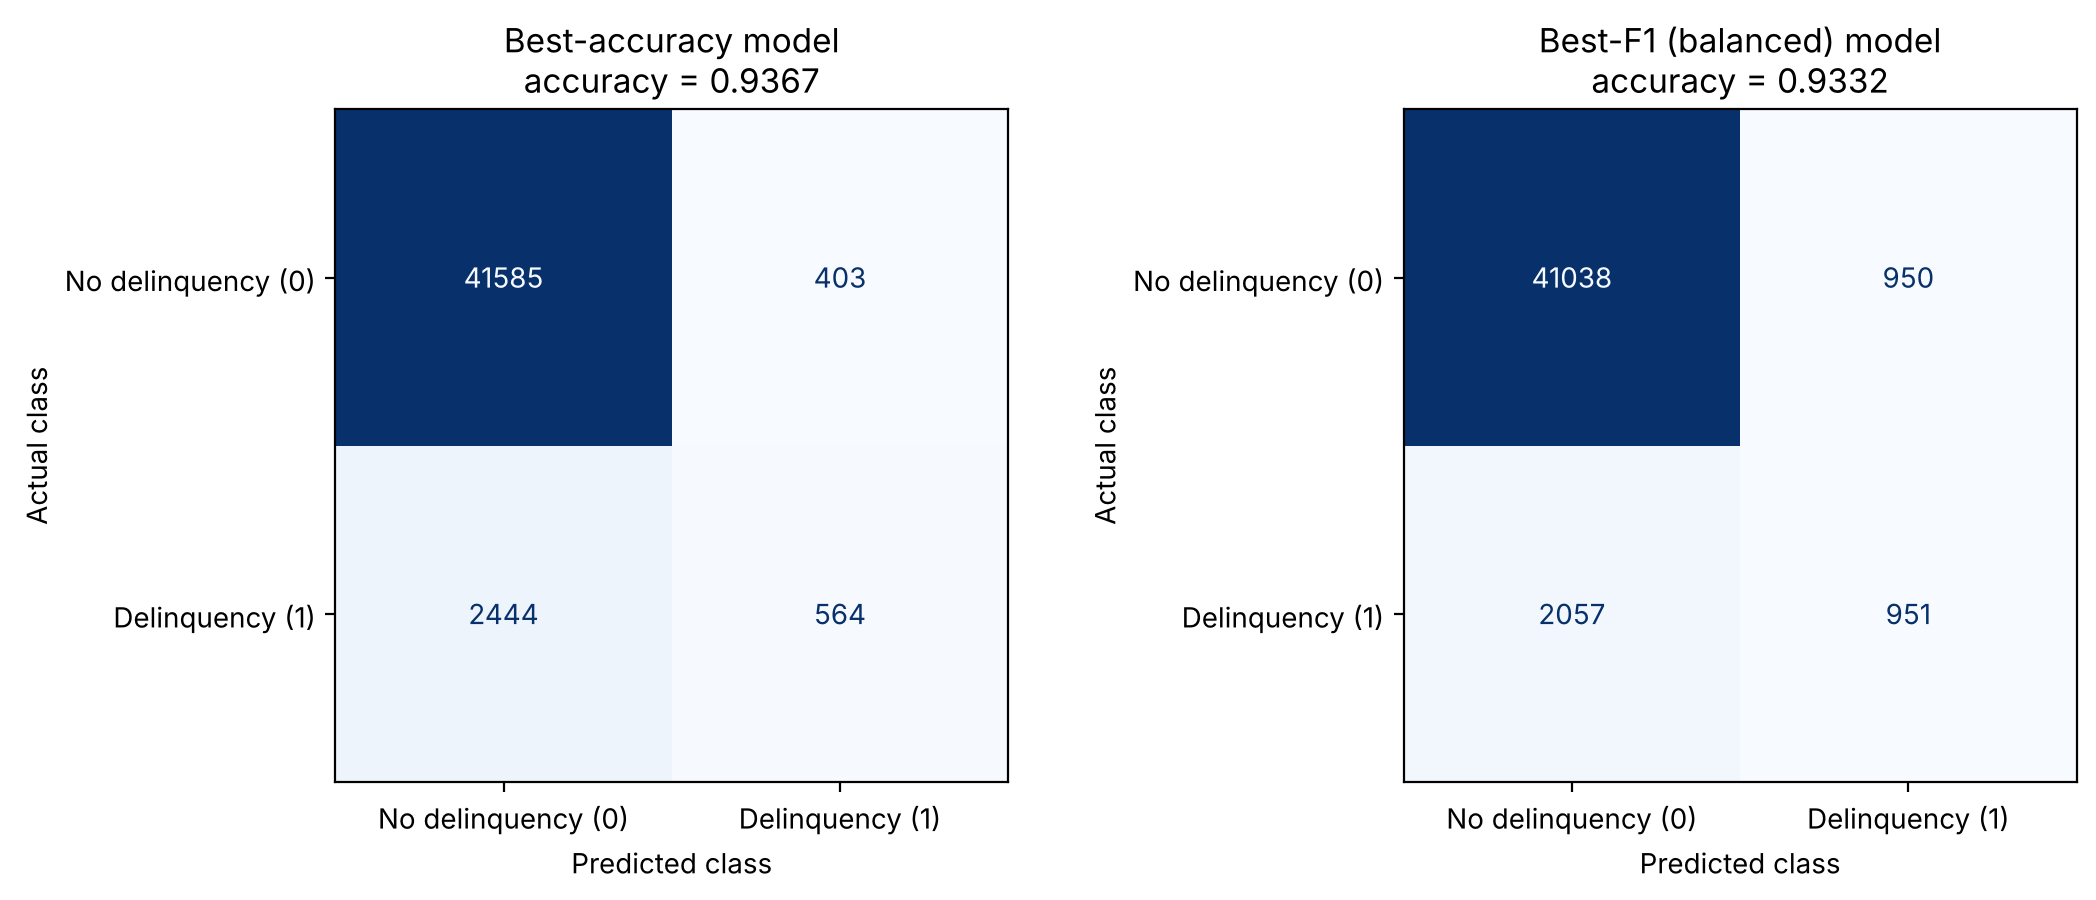

                precision    recall  f1-score   support

No delinquency       0.94      0.99      0.97     41988
   Delinquency       0.58      0.19      0.28      3008

      accuracy                           0.94     44996
     macro avg       0.76      0.59      0.63     44996
  weighted avg       0.92      0.94      0.92     44996



In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (title, m) in zip(axes, [('Best-accuracy model', final_acc), ('Best-F1 (balanced) model', final_f1)]):
    p = m.predict(X_test)
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=['No delinquency (0)', 'Delinquency (1)']).plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(f'{title}\naccuracy = {accuracy_score(y_test, p):.4f}'); ax.set_xlabel('Predicted class'); ax.set_ylabel('Actual class')
plt.tight_layout(); plt.show()
print(classification_report(y_test, final_acc.predict(X_test), target_names=['No delinquency', 'Delinquency']))

### Conclusion for part C

- **Best model for accuracy:** `HistGradientBoostingClassifier` trained on rows without the extreme outliers, **without** SMOTENC, with `learning_rate=0.05`, `max_iter=200`, `max_depth=3`, `min_samples_leaf=200`, `l2_regularization=1.0` (found by 15-candidate randomized search, 3-fold CV accuracy 0.9391 on the fitting rows, validation accuracy 0.9373). **Test accuracy: 0.9367**, up from 0.9349 for the baseline Random Forest and 0.9331 for the do-nothing baseline: a real but very small gain (+0.18 percentage points ≈ 80 more correct customers out of 44,996). Its delinquency recall is still only 0.19, so it is not a better *detector*.
- **Balancing is the only step that actually helps detect delinquency.** The best-F1 variant (HistGradientBoosting + SMOTENC, default hyper-parameters) lifts delinquency recall from 0.19 to **0.32** and F1 from 0.28 to **0.39** at the cost of accuracy (0.9332, i.e. no better than always predicting "no delinquency"). Which model is "best" therefore depends on the lender's costs; for a credit-risk use case the balanced model (or a lower decision threshold on a probability model) is the sensible choice even though its accuracy is lower.
- Caveat: the validation grid, the 15-candidate search and a 30 % SMOTENC ratio are small experiments; accuracy differences of 0.001-0.002 should not be over-interpreted.

## Key takeaways

- Fit the model on training rows and evaluate on held-out rows; choose techniques on a validation split, not on the test set.
- Keep preprocessing and predictor schemas consistent across datasets.
- Inspect delinquency precision and recall alongside accuracy: with ~6.7 % positives, accuracy is dominated by the majority class.
- Interpret errors in terms of the decisions they would affect.